# Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.metrics import adjusted_rand_score, silhouette_score

# Generate data with make_moons

In [2]:
X, y = make_moons(n_samples=300, noise=0.05, random_state=42)
df = pd.DataFrame(X, columns=['x1', 'x2'])
df.head()

,x1,x2
0,0.622519,-0.372101
1,1.904269,-0.136303
2,-0.069431,0.456117
3,0.933899,0.237483
4,1.180360,-0.490847


# Show info

In [3]:
df.info()
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      300 non-null    float64
 1   x2      300 non-null    float64
dtypes: float64(2)
memory usage: 4.8 KB
               x1          x2
count  300.000000  300.000000
mean     0.500413    0.253196
std      0.871355    0.496069
min     -1.104663   -0.563235
25%     -0.063124   -0.197303
50%      0.485312    0.248550
75%      1.047578    0.713130
max      2.131198    1.107772


# 2D Plotting of the original data

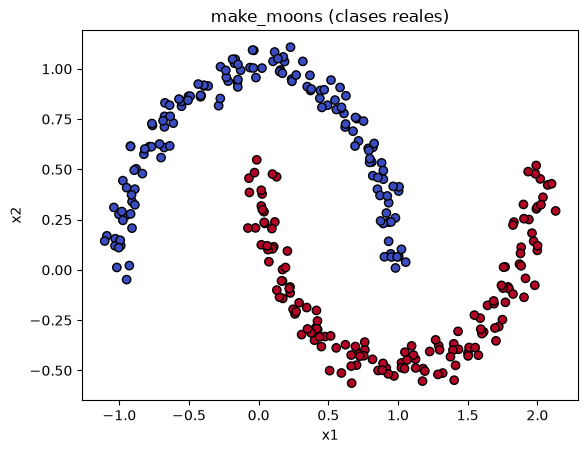

In [4]:
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('make_moons (clases reales)')
plt.show()

# K-means from scratch (Euclidean kernel)

K-means asigna cada punto al centroide más cercano usando la distancia euclidiana, es decir, el producto punto lineal $k(x, y) = x^T y$.

In [5]:
def kmeans(X, k, max_iter=100, seed=0):
    rng = np.random.RandomState(seed)
    centroids = X[rng.choice(len(X), k, replace=False)]
    for _ in range(max_iter):
        # distancia de cada punto a cada centroide
        dist = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
        labels = dist.argmin(axis=1)
        new_centroids = np.array([X[labels == c].mean(axis=0) for c in range(k)])
        if np.allclose(new_centroids, centroids):
            break
        centroids = new_centroids
    return labels, centroids

In [6]:
labels_lin, centroids_lin = kmeans(X, k=2)
print('ARI (kernel lineal):', adjusted_rand_score(y, labels_lin))
print('Silhouette (kernel lineal):', silhouette_score(X, labels_lin))

ARI (kernel lineal): 0.24748333370867506
Silhouette (kernel lineal): 0.4876880352207799


# Predefined function (KMeans)

In [7]:
km = KMeans(n_clusters=2, n_init=10, random_state=0)
labels_km = km.fit_predict(X)
print('ARI (sklearn KMeans):', adjusted_rand_score(y, labels_km))

ARI (sklearn KMeans): 0.24748333370867506


# Plotting linear k-means

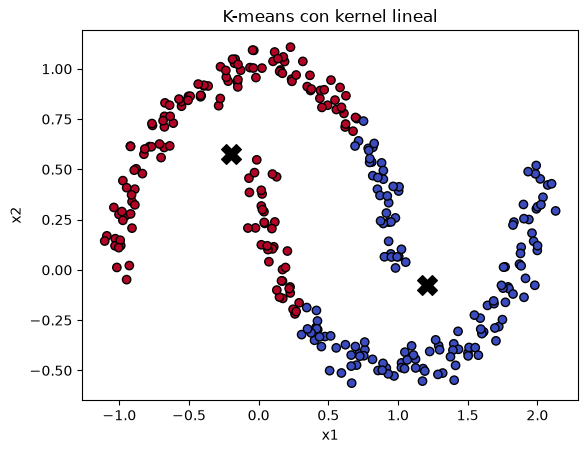

In [8]:
plt.scatter(X[:, 0], X[:, 1], c=labels_lin, cmap='coolwarm', edgecolor='k')
plt.scatter(centroids_lin[:, 0], centroids_lin[:, 1], c='black', marker='X', s=200)
plt.title('K-means con kernel lineal')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()

# Kernel change: RBF kernel matrix

Los datos no son linealmente separables, por lo que se cambia el kernel lineal por uno gaussiano (RBF):

$$k(x_i, x_j) = \exp(-\gamma \|x_i - x_j\|^2)$$

Este kernel mide similitud por vecindad, no por distancia a un centro.

In [9]:
gamma = 15
K = rbf_kernel(X, gamma=gamma)
print(K.shape)
print(K[:5, :5])

(300, 300)
[[1.00000000e+00 8.61714961e-12 2.58458838e-08 8.86480973e-04
  7.60236183e-03]
 [8.61714961e-12 1.00000000e+00 2.17178833e-28 9.03092310e-08
  5.85164666e-05]
 [2.58458838e-08 2.17178833e-28 1.00000000e+00 1.35123430e-07
  9.61362404e-17]
 [8.86480973e-04 9.03092310e-08 1.35123430e-07 1.00000000e+00
  1.40808772e-04]
 [7.60236183e-03 5.85164666e-05 9.61362404e-17 1.40808772e-04
  1.00000000e+00]]


# Normalized kernel

Se normaliza la matriz de kernel con la matriz de grados $D$ para que clusters con muchos puntos no dominen:

$$K_{norm} = D^{-1/2} K D^{-1/2}$$

In [10]:
d = K.sum(axis=1)
K_norm = K / np.sqrt(np.outer(d, d))
print(K_norm[:5, :5])

[[4.80926469e-02 4.63739393e-13 1.64314122e-09 4.42144114e-05
  3.63942349e-04]
 [4.63739393e-13 6.02201775e-02 1.54501491e-29 5.04032162e-09
  3.13468444e-06]
 [1.64314122e-09 1.54501491e-29 8.40404419e-02 8.90901959e-09
  6.08381523e-18]
 [4.42144114e-05 5.04032162e-09 8.90901959e-09 5.17261529e-02
  6.99084252e-06]
 [3.63942349e-04 3.13468444e-06 6.08381523e-18 6.99084252e-06
  4.76529110e-02]]


# Eigenvalues and eigenvectors of the kernel

In [11]:
eigenvalues, eigenvectors = np.linalg.eigh(K_norm)
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]
print('eigenvalues (top 5): ', eigenvalues[:5])

eigenvalues (top 5):  [1.         0.9952443  0.9786132  0.97720147 0.92922681]


# Data transformation to the new feature space

In [12]:
k = 2
V = eigenvectors[:, :k]
Z = V / np.linalg.norm(V, axis=1, keepdims=True)   # normalización por fila
Z_df = pd.DataFrame(Z, columns=['kernel component 1', 'kernel component 2'])
Z_df.head()

,kernel component 1,kernel component 2
0,0.749605,-0.661886
1,0.621524,-0.783395
2,0.904524,-0.426422
3,0.859672,0.510847
4,0.692269,-0.721640


# K-means in the kernel space

In [13]:
labels_rbf, centroids_rbf = kmeans(Z, k=2)
print('ARI (kernel RBF):', adjusted_rand_score(y, labels_rbf))
print('Silhouette (kernel RBF, espacio original):', silhouette_score(X, labels_rbf))

ARI (kernel RBF): 1.0
Silhouette (kernel RBF, espacio original): 0.33078776489960326


# Plotting kernel space and original space

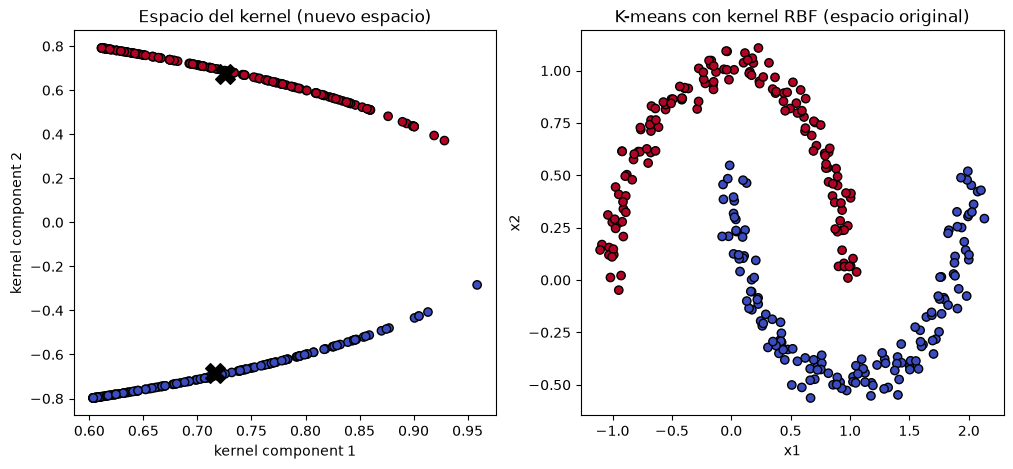

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(Z[:, 0], Z[:, 1], c=labels_rbf, cmap='coolwarm', edgecolor='k')
ax[0].scatter(centroids_rbf[:, 0], centroids_rbf[:, 1], c='black', marker='X', s=200)
ax[0].set_title('Espacio del kernel (nuevo espacio)')
ax[0].set_xlabel('kernel component 1')
ax[0].set_ylabel('kernel component 2')

ax[1].scatter(X[:, 0], X[:, 1], c=labels_rbf, cmap='coolwarm', edgecolor='k')
ax[1].set_title('K-means con kernel RBF (espacio original)')
ax[1].set_xlabel('x1')
ax[1].set_ylabel('x2')
plt.show()

# Predefined function (SpectralClustering) to validate

In [15]:
sc = SpectralClustering(n_clusters=2, affinity='rbf', gamma=gamma, random_state=0)
labels_sc = sc.fit_predict(X)
print('ARI (sklearn SpectralClustering):', adjusted_rand_score(y, labels_sc))
print('Coincidencia con la implementación propia:', adjusted_rand_score(labels_sc, labels_rbf))

ARI (sklearn SpectralClustering): 1.0
Coincidencia con la implementación propia: 1.0


# Comparison

                       Método       ARI
0     K-means (kernel lineal)  0.247483
1              KMeans sklearn  0.247483
2        K-means (kernel RBF)  1.000000
3  SpectralClustering sklearn  1.000000


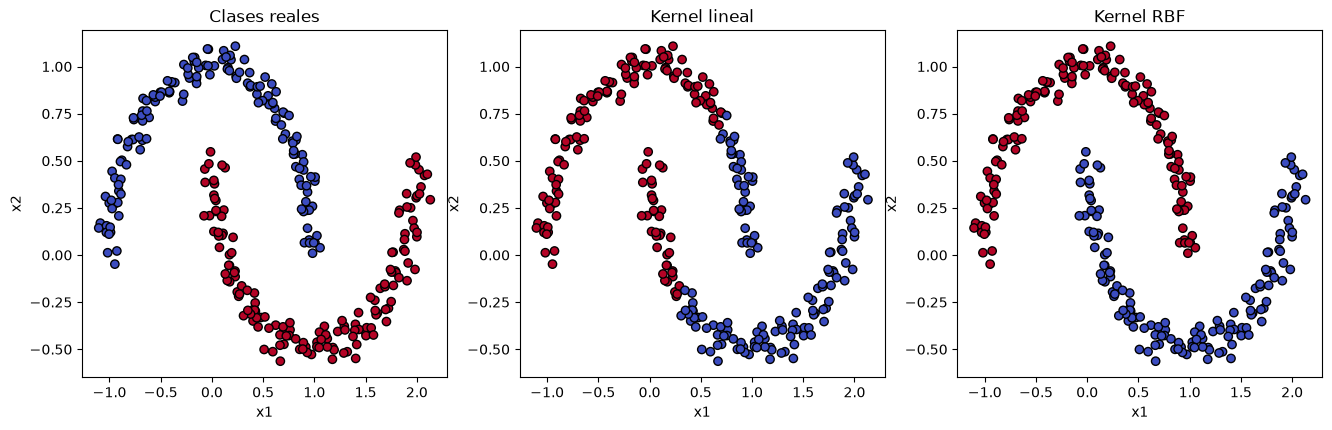

In [16]:
results = pd.DataFrame({
    'Método': ['K-means (kernel lineal)', 'KMeans sklearn', 'K-means (kernel RBF)', 'SpectralClustering sklearn'],
    'ARI': [adjusted_rand_score(y, l) for l in [labels_lin, labels_km, labels_rbf, labels_sc]]
})
print(results)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, l, t in zip(ax, [y, labels_lin, labels_rbf], ['Clases reales', 'Kernel lineal', 'Kernel RBF']):
    a.scatter(X[:, 0], X[:, 1], c=l, cmap='coolwarm', edgecolor='k')
    a.set_title(t)
    a.set_xlabel('x1')
    a.set_ylabel('x2')
plt.show()

# Effect of gamma

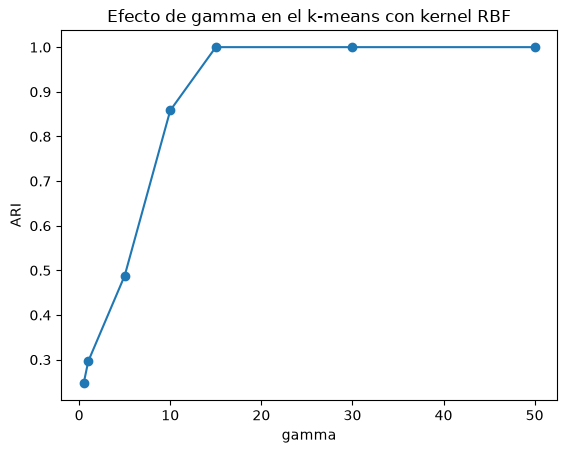

   gamma       ARI
0    0.5  0.247483
1    1.0  0.296492
2    5.0  0.488289
3   10.0  0.858237
4   15.0  1.000000
5   30.0  1.000000
6   50.0  1.000000


In [17]:
gammas = [0.5, 1, 5, 10, 15, 30, 50]
aris = []
for g in gammas:
    Kg = rbf_kernel(X, gamma=g)
    dg = Kg.sum(axis=1)
    Kn = Kg / np.sqrt(np.outer(dg, dg))
    w, v = np.linalg.eigh(Kn)
    v = v[:, np.argsort(w)[::-1][:2]]
    Zg = v / np.linalg.norm(v, axis=1, keepdims=True)
    lg, _ = kmeans(Zg, k=2)
    aris.append(adjusted_rand_score(y, lg))

plt.plot(gammas, aris, marker='o')
plt.xlabel('gamma')
plt.ylabel('ARI')
plt.title('Efecto de gamma en el k-means con kernel RBF')
plt.show()
print(pd.DataFrame({'gamma': gammas, 'ARI': aris}))

## Conclusión

Este programa implementó el algoritmo k-means con cambio de kernel sobre el conjunto de datos generado con `make_moons`. Primero se programó k-means desde cero con distancia euclidiana (kernel lineal) y se comprobó que no logra separar las dos lunas, ya que asume clusters convexos alrededor de un centroide y divide los datos con una línea recta.

Después se sustituyó el kernel lineal por un kernel gaussiano (RBF), se normalizó la matriz de kernel, se calcularon sus valores y vectores propios y se aplicó k-means en el nuevo espacio. En esa representación las dos lunas se vuelven separables y el algoritmo recupera los grupos reales (ARI cercano a 1), con un resultado equivalente al de `SpectralClustering` de sklearn, lo que valida la implementación.
`SpectralClustering` de sklearn es un algoritmo de agrupamiento que construye un grafo de afinidad entre los puntos y utiliza los vectores propios de su matriz para representarlos en un espacio donde los grupos pueden separarse mejor. Después, asigna los puntos a los clusters. En este caso, `affinity='rbf'` usa una similitud gaussiana y `gamma` controla su alcance. Se incluye como referencia para comparar los resultados con la implementación propia.

También se observó que el parámetro `gamma` es determinante: valores pequeños hacen que el kernel sea casi lineal y no separa las lunas, mientras que valores adecuados capturan la estructura local de los datos. En resumen, el cambio de kernel permite que k-means resuelva problemas no lineales sin modificar su lógica de asignación y actualización.